# Lab Assignment 10 — Semantic IR Using LSA and Word2Vec
**IT550: Information Retrieval** · Instructor: Prof. Sandip Modha
**Student ID:** 202303022

This notebook builds and evaluates

1. a **TF-IDF vector-space baseline** on the Cranfield collection (Part 1),
2. a **Latent Semantic Analysis (LSA)** retrieval system using truncated SVD (Part 2),
3. an **evaluation and dimensionality analysis** of LSA against the baseline with P@5, MAP and nDCG@10 (Part 3),
4. **Word2Vec** embeddings (CBOW and Skip-gram), compared with count-based (TF-IDF and PPMI co-occurrence) word similarity (Part 4).

All results below were produced by running the notebook top to bottom. Rankings, tables, figures and a
machine-readable `results.json` are written to `outputs/`.

In [1]:
import json, re, time, zlib, platform
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

import scipy.sparse as sp
import sklearn, gensim, nltk
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from nltk.stem import PorterStemmer
from gensim.models import Word2Vec

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

DATA = Path("data")
OUT = Path("outputs")
for sub in ["rankings", "figures", "tables"]:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

RESULTS = {}   # everything that goes into outputs/results.json
print("Python", platform.python_version(), "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| gensim", gensim.__version__, "| nltk", nltk.__version__)

Python 3.13.17 | numpy 2.5.3 | scikit-learn 1.9.1 | gensim 4.4.0 | nltk 3.10.4


## Dataset: Cranfield collection

* `cran.all.1400` — 1,400 aerodynamics abstracts with fields `.I` (id), `.T` (title), `.A` (author), `.B` (bibliography), `.W` (abstract).
* `cran.qry` — 225 queries. The `.I` numbers in this file are **not** consecutive (001, 002, 004, …); `cranqrel` numbers the
  queries **1–225 in file order**, so query *i* in `cranqrel` is the *i*-th query of `cran.qry`.
* `cranqrel` — lines `query doc grade`. Grades: 1 = most relevant … 4 = minimal interest, and −1 (one per query).

As required by the lab:

* a document is **relevant** for P@5 and MAP if its grade is **1, 2 or 3**;
* the **nDCG gain is `4 − grade`** (grade 1 → 3, grade 2 → 2, grade 3 → 1, grade 4 → 0); grade −1 is not relevant and gets no gain;
* only queries with **at least one relevant document** are evaluated.

In [2]:
def parse_cran_docs(path):
    docs, cur, field = [], None, None
    for line in open(path, encoding="utf-8", errors="replace"):
        tag = line.strip()
        if line.startswith(".I"):
            if cur is not None:
                docs.append(cur)
            cur = {"doc_id": int(line.split()[1]), "T": [], "A": [], "B": [], "W": []}
            field = None
        elif tag in (".T", ".A", ".B", ".W"):
            field = tag[1]
        elif field is not None:
            cur[field].append(tag)
    docs.append(cur)
    return pd.DataFrame([{"doc_id": d["doc_id"],
                          "title": " ".join(d["T"]).strip(),
                          "abstract": " ".join(d["W"]).strip()} for d in docs])


def parse_cran_queries(path):
    queries, cur, field = [], None, None
    for line in open(path, encoding="utf-8", errors="replace"):
        tag = line.strip()
        if line.startswith(".I"):
            if cur is not None:
                queries.append(cur)
            cur = {"orig_id": int(line.split()[1]), "W": []}
            field = None
        elif tag == ".W":
            field = "W"
        elif field is not None:
            cur["W"].append(tag)
    queries.append(cur)
    # cranqrel numbers the queries 1..225 in file order
    return pd.DataFrame([{"qid": i + 1, "orig_id": q["orig_id"], "text": " ".join(q["W"]).strip()}
                         for i, q in enumerate(queries)])


docs_df = parse_cran_docs(DATA / "cran.all.1400")
queries_df = parse_cran_queries(DATA / "cran.qry")
qrels_df = pd.read_csv(DATA / "cranqrel", sep=r"\s+", header=None, names=["qid", "doc_id", "grade"])

# Title and abstract are indexed together
docs_df["text"] = (docs_df["title"] + " " + docs_df["abstract"]).str.strip()
assert docs_df["doc_id"].tolist() == list(range(1, len(docs_df) + 1))

print(f"documents: {len(docs_df)}   queries: {len(queries_df)}   qrels lines: {len(qrels_df)}")
print("grade distribution:", qrels_df["grade"].value_counts().sort_index().to_dict())
print("documents with an empty abstract:", (docs_df['abstract'] == '').sum())
display(docs_df.head(3)[["doc_id", "title", "abstract"]])
display(queries_df.head(5))

documents: 1400   queries: 225   qrels lines: 1837
grade distribution: {-1: 225, 1: 128, 2: 387, 3: 734, 4: 363}
documents with an empty abstract: 2


,doc_id,title,abstract
0,1,experimental investigation of the aerodynamics of a wing in a slipstream .,experimental investigation of the aerodynamics of a wing in a slipstream . an experimental study of a wing in a prop...
1,2,simple shear flow past a flat plate in an incompressible fluid of small viscosity .,simple shear flow past a flat plate in an incompressible fluid of small viscosity . in the study of high-speed visco...
2,3,the boundary layer in simple shear flow past a flat plate .,the boundary layer in simple shear flow past a flat plate . the boundary-layer equations are presented for steady in...


,qid,orig_id,text
0,1,1,what similarity laws must be obeyed when constructing aeroelastic models of heated high speed aircraft .
1,2,2,what are the structural and aeroelastic problems associated with flight of high speed aircraft .
2,3,4,what problems of heat conduction in composite slabs have been solved so far .
3,4,8,can a criterion be developed to show empirically the validity of flow solutions for chemically reacting gas mixtures...
4,5,9,what chemical kinetic system is applicable to hypersonic aerodynamic problems .


In [3]:
# Relevance sets (grade 1-3) and graded gains (4 - grade) per query
REL_GRADES = {1, 2, 3}
relevant = defaultdict(set)
gains = defaultdict(dict)
for q, d, g in qrels_df.itertuples(index=False):
    if g in REL_GRADES:
        relevant[q].add(d)
        gains[q][d] = 4 - g

eval_qids = [q for q in queries_df["qid"] if len(relevant[q]) > 0]
skipped = [q for q in queries_df["qid"] if len(relevant[q]) == 0]
n_rel = [len(relevant[q]) for q in eval_qids]
print(f"queries with >= 1 relevant document (evaluated): {len(eval_qids)} of {len(queries_df)}")
print("queries without any relevant document (skipped):",
      queries_df.set_index("qid").loc[skipped, "orig_id"].to_dict(), "(qid -> original .I)")
print(f"relevant docs per evaluated query: mean {np.mean(n_rel):.2f}, min {min(n_rel)}, max {max(n_rel)}")
RESULTS["dataset"] = {"n_docs": len(docs_df), "n_queries": len(queries_df), "n_qrels": len(qrels_df),
                      "n_eval_queries": len(eval_qids), "skipped_qids": skipped,
                      "mean_rel_per_query": float(np.mean(n_rel))}

queries with >= 1 relevant document (evaluated): 222 of 225
queries without any relevant document (skipped): {31: 56, 119: 173, 215: 339} (qid -> original .I)
relevant docs per evaluated query: mean 5.63, min 1, max 36


## Part 1 — Corpus preparation and TF-IDF baseline

**Preprocessing pipeline** (identical for documents and queries):

1. lower-casing;
2. tokenisation with the regular expression `[a-z]+` (splits on punctuation, hyphens and digits);
3. stop-word removal with scikit-learn's English stop-word list (318 words) and removal of 1-character tokens;
4. Porter stemming (NLTK).

In [4]:
STOP = frozenset(ENGLISH_STOP_WORDS)
TOKEN_RE = re.compile(r"[a-z]+")
stemmer = PorterStemmer()
_stem_cache = {}

def tokenize(text):
    # steps 1-3: lowercase, tokenise, drop stop words and 1-character tokens
    return [t for t in TOKEN_RE.findall(text.lower()) if t not in STOP and len(t) > 1]

def stem(token):
    if token not in _stem_cache:
        _stem_cache[token] = stemmer.stem(token)
    return _stem_cache[token]

def preprocess(text):
    # full pipeline used as the TfidfVectorizer analyzer
    return [stem(t) for t in tokenize(text)]

example = queries_df.loc[0, "text"]
print("raw      :", example)
print("tokens   :", tokenize(example))
print("stemmed  :", preprocess(example))

doc_tokens = [preprocess(t) for t in docs_df["text"]]
doc_lens = np.array([len(t) for t in doc_tokens])
print(f"\ntokens per document after preprocessing: mean {doc_lens.mean():.1f}, median {np.median(doc_lens):.0f}, "
      f"total {doc_lens.sum():,}")

raw      : what similarity laws must be obeyed when constructing aeroelastic models of heated high speed aircraft .
tokens   : ['similarity', 'laws', 'obeyed', 'constructing', 'aeroelastic', 'models', 'heated', 'high', 'speed', 'aircraft']
stemmed  : ['similar', 'law', 'obey', 'construct', 'aeroelast', 'model', 'heat', 'high', 'speed', 'aircraft']



tokens per document after preprocessing: mean 94.1, median 84, total 131,725


**TF-IDF document–term matrix.** `TfidfVectorizer` with the analyzer above, raw term frequency,
smoothed IDF `idf(t) = ln((1+N)/(1+df(t))) + 1` and L2-normalised rows. The vectorizer is fitted on the
documents only; queries are transformed with the **same vocabulary and IDF weights** (`transform`), so
out-of-vocabulary query terms are ignored.

In [5]:
t0 = time.perf_counter()
tfidf = TfidfVectorizer(analyzer=preprocess)
X = tfidf.fit_transform(docs_df["text"])          # documents x terms (sparse CSR)
tfidf_fit_time = time.perf_counter() - t0
vocab = tfidf.get_feature_names_out()

Q = tfidf.transform(queries_df["text"])           # queries x terms, same vocabulary + IDF
n_docs, n_terms = X.shape
sparsity = 1 - X.nnz / (n_docs * n_terms)

summary = pd.DataFrame({
    "value": [n_docs, len(queries_df), n_terms, f"{X.shape[0]} x {X.shape[1]}", f"{X.nnz:,}",
              f"{X.nnz / n_docs:.1f}", f"{100 * sparsity:.2f} %", f"{Q.shape[0]} x {Q.shape[1]}",
              f"{100 * (1 - Q.nnz / (Q.shape[0] * Q.shape[1])):.2f} %"]},
    index=["documents", "queries", "vocabulary size", "TF-IDF matrix shape", "non-zero entries",
           "avg non-zeros per document", "sparsity of document matrix", "query matrix shape",
           "sparsity of query matrix"])
display(summary)

oov = Counter(t for q in queries_df["text"] for t in preprocess(q) if t not in tfidf.vocabulary_)
print("query stems not in the document vocabulary:", dict(oov))
RESULTS["tfidf"] = {"vocab_size": int(n_terms), "shape": [int(n_docs), int(n_terms)], "nnz": int(X.nnz),
                    "sparsity": float(sparsity), "fit_time_s": tfidf_fit_time,
                    "query_shape": list(map(int, Q.shape)), "query_oov_terms": dict(oov)}

,value
documents,1400
queries,225
vocabulary size,4170
TF-IDF matrix shape,1400 x 4170
non-zero entries,"77,560"
avg non-zeros per document,55.4
sparsity of document matrix,98.67 %
query matrix shape,225 x 4170
sparsity of query matrix,99.77 %


query stems not in the document vocabulary: {'validli': 1, 'trust': 1, 'multhopp': 1, 'stop': 1, 'unnecessarili': 1, 'virtu': 1, 'orthodox': 1, 'wildli': 1, 'realiti': 1}


In [6]:
def rank_all(sim):
    # sim: queries x docs. Returns doc ids ranked by descending score (ties broken by doc id).
    order = np.argsort(-sim, axis=1, kind="stable")
    return order + 1, np.take_along_axis(sim, order, axis=1)

def save_top10(ranked, scores, run_name):
    rows = []
    for i, qid in enumerate(queries_df["qid"]):
        for r in range(10):
            rows.append((qid, queries_df.loc[i, "orig_id"], r + 1, int(ranked[i, r]), float(scores[i, r])))
    df = pd.DataFrame(rows, columns=["qid", "orig_query_id", "rank", "doc_id", "score"])
    df.to_csv(OUT / "rankings" / f"{run_name}_top10.csv", index=False)
    # the same ranking in TREC run format: qid Q0 docid rank score tag
    with open(OUT / "rankings" / f"{run_name}_top10.trec", "w") as f:
        for r in df.itertuples(index=False):
            f.write(f"{r.qid} Q0 {r.doc_id} {r.rank} {r.score:.6f} {run_name}\n")
    return df

query_times = []
for _ in range(3):                                  # median of 3 runs
    t0 = time.perf_counter()
    sim_tfidf = cosine_similarity(Q, X)             # 225 x 1400
    ranked_tfidf, scores_tfidf = rank_all(sim_tfidf)
    query_times.append(time.perf_counter() - t0)
tfidf_query_time = float(np.median(query_times))
top10_tfidf = save_top10(ranked_tfidf, scores_tfidf, "tfidf_baseline")
print(f"scored and ranked {Q.shape[0]} queries against {n_docs} documents in {tfidf_query_time*1000:.1f} ms")
print("saved -> outputs/rankings/tfidf_baseline_top10.csv / .trec")

q0 = 0
print("\nQuery 1:", queries_df.loc[q0, "text"])
show = top10_tfidf[top10_tfidf.qid == 1].copy()
show["relevant (grade)"] = [qrels_df.query("qid == 1 and doc_id == @d")["grade"].tolist() or "-" for d in show.doc_id]
show["title"] = [docs_df.loc[d - 1, "title"][:80] for d in show.doc_id]
display(show[["rank", "doc_id", "score", "relevant (grade)", "title"]])

scored and ranked 225 queries against 1400 documents in 26.0 ms
saved -> outputs/rankings/tfidf_baseline_top10.csv / .trec

Query 1: what similarity laws must be obeyed when constructing aeroelastic models of heated high speed aircraft .


,rank,doc_id,score,relevant (grade),title
0,1,51,0.329344,[3],theory of aircraft structural models subjected to aerodynamic heating and extern
1,2,184,0.286332,[2],scale models for thermo-aeroelastic research .
2,3,12,0.258925,[3],some structural and aerelastic considerations of high speed flight .
3,4,746,0.255323,-,aeroelastic problems in connection with high speed flight .
4,5,359,0.233029,-,note on the hypersonic similarity law for an unyawed cone .
5,6,13,0.224003,[4],similarity laws for stressing heated wings .
6,7,875,0.216945,[2],models for aeroelastic investigation .
7,8,435,0.197216,-,application of similar solutions to calculations of laminar heat transfer on bod
8,9,486,0.195171,[-1],similarity laws for aerothermoelastic testing .
9,10,879,0.193430,[3],flutter model testing at transonic speeds .


## Part 2 — Truncated SVD and the LSA representation

The TF-IDF matrix is factorised as $X \approx U_k \Sigma_k V_k^\top$ (documents × terms).
Documents are represented in the $k$-dimensional latent space by $X V_k = U_k\Sigma_k$ and a query vector
$q$ is folded into **the same space** by $q V_k$ (this is exactly `TruncatedSVD.fit_transform` / `transform`).
Documents are then ranked by cosine similarity in that space.

$k = 50$ is valid here: it is far below $\min(1400, |V|) - 1$.

In [7]:
def run_lsa(k, seed=SEED, repeats=3):
    # runtimes are the median over `repeats` identical runs
    assert 0 < k < min(X.shape), f"k={k} is not valid for a {X.shape} matrix"
    fit_times, query_times = [], []
    for _ in range(repeats):
        t0 = time.perf_counter()
        svd = TruncatedSVD(n_components=k, algorithm="randomized", n_iter=10, random_state=seed)
        D_k = svd.fit_transform(X)                # documents in latent space (= U_k Sigma_k)
        fit_times.append(time.perf_counter() - t0)
        t0 = time.perf_counter()
        Q_k = svd.transform(Q)                    # queries folded in (= q V_k)
        sim = cosine_similarity(Q_k, D_k)
        ranked, scores = rank_all(sim)
        query_times.append(time.perf_counter() - t0)
    fit_time, query_time = float(np.median(fit_times)), float(np.median(query_times))
    energy = float((svd.singular_values_ ** 2).sum() / X.multiply(X).sum())
    return dict(k=k, svd=svd, D=D_k, Q=Q_k, sim=sim, ranked=ranked, scores=scores, fit_time=fit_time,
                query_time=query_time, explained_variance=float(svd.explained_variance_ratio_.sum()),
                energy=energy)

K_MAIN = 50
lsa50 = run_lsa(K_MAIN)
top10_lsa50 = save_top10(lsa50["ranked"], lsa50["scores"], f"lsa_k{K_MAIN}")

print(f"k = {K_MAIN}")
print(f"  explained variance ratio of the retained components (sum): {lsa50['explained_variance']:.4f}"
      f"  ({100*lsa50['explained_variance']:.2f} %)")
print(f"  share of the squared Frobenius norm kept, sum(s_i^2)/||X||_F^2: {lsa50['energy']:.4f}")
print(f"  document matrix in latent space: {lsa50['D'].shape}")
print(f"  query matrix in latent space   : {lsa50['Q'].shape}")
print(f"  V_k (term loadings) shape      : {lsa50['svd'].components_.T.shape}")
print(f"  SVD fit time {lsa50['fit_time']:.3f} s, folding + ranking time {lsa50['query_time']*1000:.1f} ms")
print("saved -> outputs/rankings/lsa_k50_top10.csv / .trec")

RESULTS["lsa_k50"] = {"explained_variance": lsa50["explained_variance"], "energy": lsa50["energy"],
                      "doc_shape": list(lsa50["D"].shape), "query_shape": list(lsa50["Q"].shape),
                      "first10_component_evr": lsa50["svd"].explained_variance_ratio_[:10].tolist()}

k = 50
  explained variance ratio of the retained components (sum): 0.3115  (31.15 %)
  share of the squared Frobenius norm kept, sum(s_i^2)/||X||_F^2: 0.3488
  document matrix in latent space: (1400, 50)
  query matrix in latent space   : (225, 50)
  V_k (term loadings) shape      : (4170, 50)
  SVD fit time 0.205 s, folding + ranking time 36.6 ms
saved -> outputs/rankings/lsa_k50_top10.csv / .trec


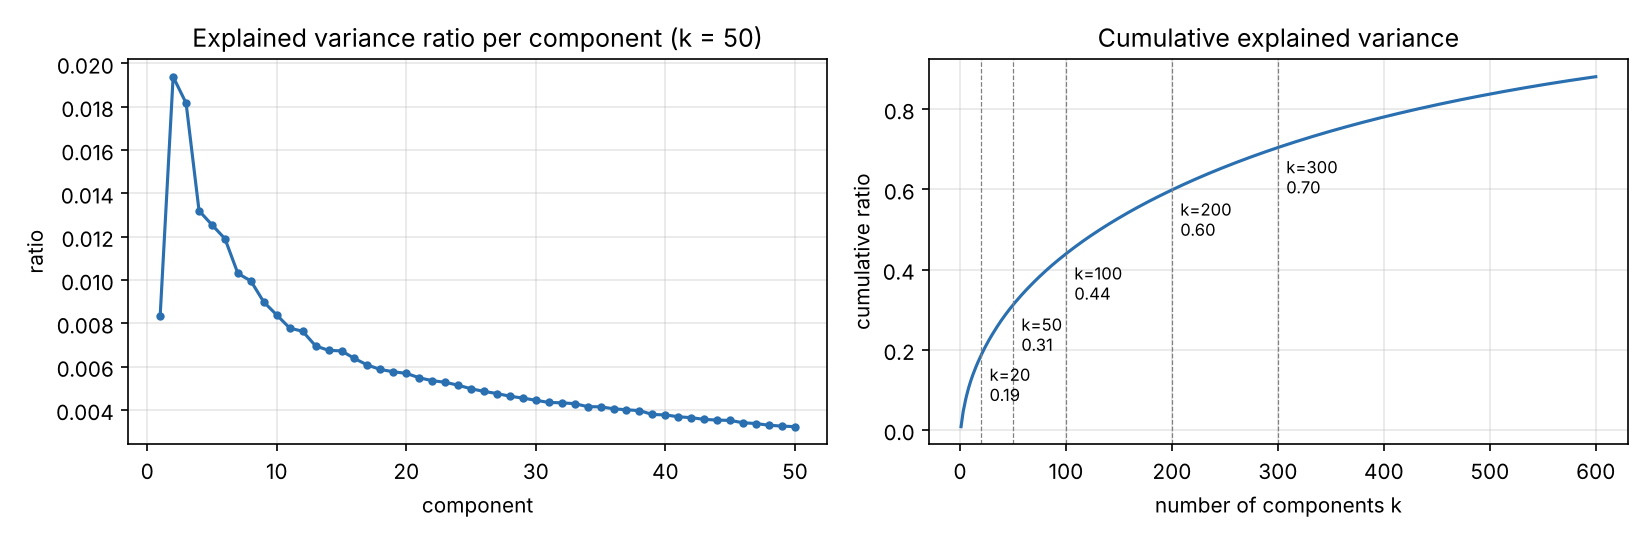

{'10': 0.121, '20': 0.187, '50': 0.312, '100': 0.439, '200': 0.599, '300': 0.704, '400': 0.78, '500': 0.837, '600': 0.881}


In [8]:
# Explained variance per component and cumulative (computed once with a large k for the curve)
svd_big = TruncatedSVD(n_components=600, algorithm="randomized", n_iter=10, random_state=SEED).fit(X)
cum = np.cumsum(svd_big.explained_variance_ratio_)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(np.arange(1, 51), lsa50["svd"].explained_variance_ratio_, marker=".", color="#2a6fb0")
ax[0].set(title="Explained variance ratio per component (k = 50)", xlabel="component", ylabel="ratio")
ax[1].plot(np.arange(1, len(cum) + 1), cum, color="#2a6fb0")
for k in (20, 50, 100, 200, 300):
    ax[1].axvline(k, color="grey", lw=0.6, ls="--")
    ax[1].annotate(f"k={k}\n{cum[k-1]:.2f}", (k, cum[k-1]), textcoords="offset points", xytext=(4, -22), fontsize=8)
ax[1].set(title="Cumulative explained variance", xlabel="number of components k", ylabel="cumulative ratio")
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "figures" / "explained_variance.png", dpi=150); plt.close()
display(Image(str(OUT / "figures" / "explained_variance.png")))
RESULTS["cumulative_evr"] = {str(k): float(cum[k - 1]) for k in (10, 20, 50, 100, 200, 300, 400, 500, 600)}
print({k: round(v, 3) for k, v in RESULTS["cumulative_evr"].items()})

In [9]:
# What do the latent dimensions encode? Top-weighted stems of the first few components.
comp_rows = []
for i in range(8):
    w = lsa50["svd"].components_[i]
    pos = vocab[np.argsort(-w)[:8]]
    neg = vocab[np.argsort(w)[:6]]
    comp_rows.append({"component": i + 1, "highest positive loadings": " ".join(pos),
                      "most negative loadings": " ".join(neg)})
display(pd.DataFrame(comp_rows).set_index("component"))

,highest positive loadings,most negative loadings
component,,
1,flow layer boundari pressur number heat bodi shock,igi mev igc terrestri juli hazard
2,wing buckl lift shell flutter load bodi theori,layer boundari heat transfer laminar turbul
3,buckl shell stress cylind load cylindr plate compress,wing bodi shock mach number jet
4,jet number heat pressur transfer mach cylind test,wing flow solut equat method lift
5,wing flutter boundari layer panel jet turbul lift,shock bodi hyperson wave blunt flow
6,heat transfer temperatur wing bodi rate thermal stagnat,jet layer boundari nozzl pressur shock
7,jet heat nozzl solut magnet fluid flow mix,shock layer wave boundari transit buckl
8,flutter shock panel wave plate temperatur ga magnet,cylind bodi cone shell circular pressur


## Part 3 — Evaluation and dimensionality analysis

Metrics (averaged over the evaluated queries):

* **P@5** — fraction of the top 5 documents that are relevant (grade 1–3).
* **MAP** — mean of average precision computed over the **full ranking** of all 1,400 documents
  (standard, uncut AP). Because only top-10 lists are saved, **MAP@10** (AP over the top 10, divided by min(|R|, 10)) is reported too.
* **nDCG@10** — $\mathrm{DCG@10} = \sum_{i=1}^{10} \frac{gain_i}{\log_2(i+1)}$ with $gain = 4 - grade$,
  normalised by the DCG of the ideal ordering of all judged relevant documents.

In [10]:
def precision_at(ranked, rel, k=5):
    return len(set(ranked[:k]) & rel) / k

def average_precision(ranked, rel, cutoff=None):
    hits, s = 0, 0.0
    for i, d in enumerate(ranked[:cutoff] if cutoff else ranked, start=1):
        if d in rel:
            hits += 1
            s += hits / i
    denom = min(len(rel), cutoff) if cutoff else len(rel)
    return s / denom

def ndcg_at(ranked, g, k=10):
    dcg = sum(g.get(d, 0) / np.log2(i + 2) for i, d in enumerate(ranked[:k]))
    ideal = sorted(g.values(), reverse=True)[:k]
    idcg = sum(v / np.log2(i + 2) for i, v in enumerate(ideal))
    return dcg / idcg

def evaluate(ranked):
    # ranked: (225, n_docs) array of doc ids. Returns per-query metrics for evaluated queries.
    rows = []
    for qid in eval_qids:
        r = ranked[qid - 1].tolist()
        rows.append({"qid": qid, "P@5": precision_at(r, relevant[qid], 5),
                     "MAP": average_precision(r, relevant[qid]),
                     "MAP@10": average_precision(r, relevant[qid], cutoff=10),
                     "nDCG@10": ndcg_at(r, gains[qid], 10)})
    return pd.DataFrame(rows).set_index("qid")

# sanity checks of the metric code on a toy ranking
assert precision_at([1, 2, 3, 4, 5], {1, 3}) == 0.4
assert abs(average_precision([1, 9, 3], {1, 3}) - (1 + 2/3) / 2) < 1e-12
assert abs(ndcg_at([5, 6], {5: 3, 6: 2}) - 1.0) < 1e-12

per_q = {"TF-IDF": evaluate(ranked_tfidf), "LSA k=50": evaluate(lsa50["ranked"])}
main_table = pd.DataFrame({name: df.mean() for name, df in per_q.items()}).T
main_table.index.name = f"system ({len(eval_qids)} queries)"
display(main_table.round(4))

,P@5,MAP,MAP@10,nDCG@10
system (222 queries),,,,
TF-IDF,0.2739,0.2912,0.2441,0.3495
LSA k=50,0.2279,0.2685,0.2186,0.3067


### 3.1 Comparing the top-10 lists of TF-IDF and LSA (k = 50)

In [11]:
overlap = np.array([len(set(ranked_tfidf[q - 1, :10]) & set(lsa50["ranked"][q - 1, :10])) for q in eval_qids])
rel_in_top10 = lambda ranked: np.array([len(set(ranked[q - 1, :10]) & relevant[q]) for q in eval_qids])
rt, rl = rel_in_top10(ranked_tfidf), rel_in_top10(lsa50["ranked"])
print(f"average overlap of the two top-10 lists: {overlap.mean():.2f} documents "
      f"(Jaccard {np.mean(overlap / (20 - overlap)):.3f})")
print("distribution of the overlap:", dict(sorted(Counter(overlap.tolist()).items())))
print(f"relevant documents in top-10: TF-IDF {rt.sum()} total ({rt.mean():.2f}/query), "
      f"LSA {rl.sum()} total ({rl.mean():.2f}/query)")
print(f"queries with no relevant document in top-10: TF-IDF {(rt == 0).sum()}, LSA {(rl == 0).sum()}")

# relevant documents found by one system's top-10 but not by the other's
only_t = sum(len((set(ranked_tfidf[q-1, :10]) - set(lsa50['ranked'][q-1, :10])) & relevant[q]) for q in eval_qids)
only_l = sum(len((set(lsa50['ranked'][q-1, :10]) - set(ranked_tfidf[q-1, :10])) & relevant[q]) for q in eval_qids)
print(f"relevant docs only in the TF-IDF top-10: {only_t}; only in the LSA top-10: {only_l}")

def side_by_side(qid):
    rows = []
    for r in range(10):
        dt, dl = int(ranked_tfidf[qid - 1, r]), int(lsa50["ranked"][qid - 1, r])
        mark = lambda d: f"{d}{' *R' + str(4 - gains[qid][d]) if d in relevant[qid] else ''}"
        rows.append({"rank": r + 1, "TF-IDF": mark(dt), "LSA k=50": mark(dl)})
    return pd.DataFrame(rows).set_index("rank")

print("\nQuery 1:", queries_df.loc[0, "text"], "   (*Rg = relevant with grade g)")
display(side_by_side(1))
RESULTS["top10_comparison"] = {"mean_overlap": float(overlap.mean()), "mean_jaccard": float(np.mean(overlap / (20 - overlap))),
                               "rel_in_top10_tfidf": int(rt.sum()), "rel_in_top10_lsa": int(rl.sum()),
                               "zero_rel_tfidf": int((rt == 0).sum()), "zero_rel_lsa": int((rl == 0).sum()),
                               "rel_only_tfidf": int(only_t), "rel_only_lsa": int(only_l)}

average overlap of the two top-10 lists: 5.23 documents (Jaccard 0.377)
distribution of the overlap: {0: 2, 1: 7, 2: 11, 3: 17, 4: 41, 5: 41, 6: 45, 7: 30, 8: 22, 9: 5, 10: 1}
relevant documents in top-10: TF-IDF 439 total (1.98/query), LSA 407 total (1.83/query)
queries with no relevant document in top-10: TF-IDF 39, LSA 52
relevant docs only in the TF-IDF top-10: 133; only in the LSA top-10: 101

Query 1: what similarity laws must be obeyed when constructing aeroelastic models of heated high speed aircraft .    (*Rg = relevant with grade g)


,TF-IDF,LSA k=50
rank,,
1,51 *R3,51 *R3
2,184 *R2,102 *R3
3,12 *R3,486
4,746,12 *R3
5,359,184 *R2
6,13,875 *R2
7,875 *R2,874
8,435,876 *R3
9,486,606


**Observations (top-10 comparison).** The two systems agree on only about half of each top-10 list
(5.2 documents on average, Jaccard 0.38), so LSA is not just re-ordering the TF-IDF ranking. LSA finds
**101** relevant documents that are missing from the TF-IDF top-10, but it also loses **133** that TF-IDF found,
so at k = 50 it ends up with fewer relevant documents in the top-10 (407 vs 439) and more queries with no relevant
document at all (52 vs 39). For query 1 both systems put doc 51 first. LSA adds the relevant docs 102 and 876, which
TF-IDF misses, and drops 879.

### 3.2 Queries where LSA improves or worsens the ranking

Per-query differences (LSA k=50 − TF-IDF) in AP and nDCG@10.

ΔMAP     : LSA better on  92 queries, worse on 124, tied on   6
ΔnDCG@10 : LSA better on  78 queries, worse on 108, tied on  36
ΔP@5     : LSA better on  40 queries, worse on  72, tied on 110

Largest improvements by LSA (sorted by ΔnDCG@10, then ΔMAP):


,query,MAP tfidf,MAP lsa,ΔMAP,nDCG@10 tfidf,nDCG@10 lsa,ΔnDCG@10
qid,,,,,,,
184,work on small-oscillation re-entry motions .,0.095,0.601,0.506,0.000,0.702,0.702
167,exact solution methods for calculating the ablative mass loss of a material ablating,0.086,0.375,0.289,0.000,0.480,0.480
180,how does scale height vary with altitude in an atmosphere .,0.204,0.527,0.323,0.354,0.831,0.477
165,are the stable profiles of a compressible boundary layer induced by a moving wave kno,0.361,1.000,0.639,0.571,1.000,0.429
53,what investigations have been made of the flow field about a body moving through a ra,0.049,0.274,0.225,0.000,0.387,0.387
95,what is the theoretical heat transfer distribution around a hemisphere .,0.077,0.200,0.123,0.000,0.387,0.387
114,it is not likely that the airforces on a wing of general planform oscillating in tran,0.090,0.380,0.290,0.224,0.609,0.385
154,which iterative method for solving linear elliptic difference equations is most rapi,0.583,1.000,0.417,0.620,1.000,0.380


Largest degradations by LSA:


,query,MAP tfidf,MAP lsa,ΔMAP,nDCG@10 tfidf,nDCG@10 lsa,ΔnDCG@10
qid,,,,,,,
136,what are the results for the creep buckling of round tubes under external pressure .,1.000,0.125,-0.875,1.000,0.315,-0.685
148,papers on small deflection theory for buckling of sandwich cylinders .,0.438,0.070,-0.368,0.655,0.000,-0.655
198,is there any information available on the difference in the effects of various edge c,0.483,0.090,-0.393,0.639,0.000,-0.639
5,what chemical kinetic system is applicable to hypersonic aerodynamic problems .,0.420,0.080,-0.340,0.582,0.000,-0.582
24,what are the factors which influence the time required to invert large structural mat,0.479,0.123,-0.356,0.721,0.154,-0.567
64,can't the static deflection shapes be used in predicting flutter in place of vibratio,0.643,0.216,-0.427,0.860,0.303,-0.557
9,papers on internal /slip flow/ heat transfer studies .,1.000,0.306,-0.694,1.000,0.444,-0.556
102,basic dynamic characteristics of structures continuous over many spans .,0.504,0.034,-0.471,0.481,0.000,-0.481


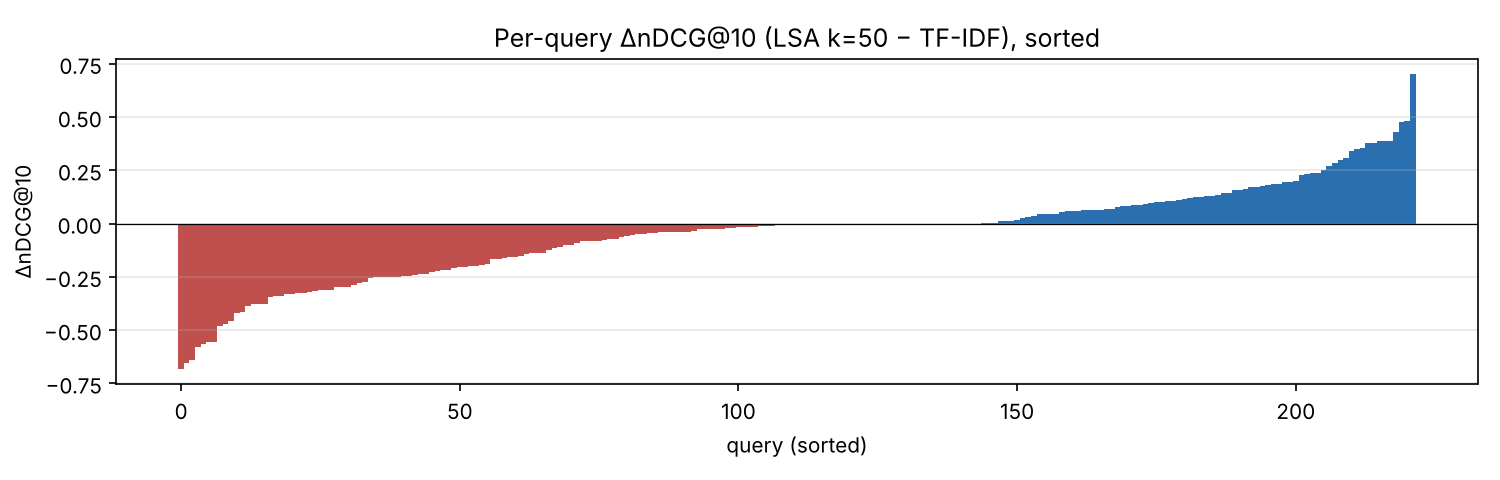

In [12]:
diff = (per_q["LSA k=50"] - per_q["TF-IDF"]).rename(columns=lambda c: "Δ" + c)
cmp_df = pd.concat([per_q["TF-IDF"].add_suffix(" tfidf"), per_q["LSA k=50"].add_suffix(" lsa"), diff], axis=1)
cmp_df.insert(0, "query", queries_df.set_index("qid").loc[cmp_df.index, "text"].str[:85])
cmp_df.to_csv(OUT / "tables" / "per_query_tfidf_vs_lsa50.csv")

for m in ["ΔMAP", "ΔnDCG@10", "ΔP@5"]:
    d = diff[m]
    print(f"{m:9s}: LSA better on {(d > 1e-9).sum():3d} queries, worse on {(d < -1e-9).sum():3d}, tied on {(abs(d) <= 1e-9).sum():3d}")

cols = ["query", "MAP tfidf", "MAP lsa", "ΔMAP", "nDCG@10 tfidf", "nDCG@10 lsa", "ΔnDCG@10"]
print("\nLargest improvements by LSA (sorted by ΔnDCG@10, then ΔMAP):")
best = cmp_df.sort_values(["ΔnDCG@10", "ΔMAP"], ascending=False).head(8)
display(best[cols].round(3))
print("Largest degradations by LSA:")
worst = cmp_df.sort_values(["ΔnDCG@10", "ΔMAP"]).head(8)
display(worst[cols].round(3))

fig, ax = plt.subplots(figsize=(10, 3.2))
d = diff["ΔnDCG@10"].sort_values().values
ax.bar(np.arange(len(d)), d, color=np.where(d >= 0, "#2a6fb0", "#c0504d"), width=1.0)
ax.axhline(0, color="black", lw=0.6)
ax.set(title="Per-query ΔnDCG@10 (LSA k=50 − TF-IDF), sorted", xlabel="query (sorted)", ylabel="ΔnDCG@10")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(OUT / "figures" / "per_query_delta_ndcg.png", dpi=150); plt.close()
display(Image(str(OUT / "figures" / "per_query_delta_ndcg.png")))

RESULTS["per_query"] = {m: {"better": int((diff[m] > 1e-9).sum()), "worse": int((diff[m] < -1e-9).sum()),
                            "tied": int((abs(diff[m]) <= 1e-9).sum())} for m in ["ΔMAP", "ΔnDCG@10", "ΔP@5"]}
RESULTS["best_queries"] = best[cols].round(4).reset_index().to_dict("records")
RESULTS["worst_queries"] = worst[cols].round(4).reset_index().to_dict("records")

In [13]:
def query_term_overlap(qid, doc_id):
    # query stems that literally occur in the document
    q = set(preprocess(queries_df.loc[qid - 1, "text"]))
    return sorted(q & set(doc_tokens[doc_id - 1]))

def explain(qid):
    qtext = queries_df.loc[qid - 1, "text"]
    print(f"qid {qid} (cran.qry .I {queries_df.loc[qid-1,'orig_id']}): {qtext}")
    print("query stems:", preprocess(qtext))
    t10, l10 = set(ranked_tfidf[qid - 1, :10]), set(lsa50["ranked"][qid - 1, :10])
    rows = []
    for d in sorted(relevant[qid], key=lambda d: -gains[qid][d]):
        rt_ = int(np.where(ranked_tfidf[qid - 1] == d)[0][0]) + 1
        rl_ = int(np.where(lsa50["ranked"][qid - 1] == d)[0][0]) + 1
        rows.append({"doc": d, "grade": 4 - gains[qid][d], "rank TF-IDF": rt_, "rank LSA": rl_,
                     "cos TF-IDF": round(float(sim_tfidf[qid - 1, d - 1]), 3),
                     "shared query stems": " ".join(query_term_overlap(qid, d)),
                     "title": docs_df.loc[d - 1, "title"][:70]})
    display(pd.DataFrame(rows).set_index("doc"))
    return t10, l10

best_qid = int(best.index[0])
print("=== Example where LSA improves the ranking ===")
t10, l10 = explain(best_qid)

=== Example where LSA improves the ranking ===
qid 184 (cran.qry .I 283): work on small-oscillation re-entry motions .
query stems: ['work', 'small', 'oscil', 'entri', 'motion']


,grade,rank TF-IDF,rank LSA,cos TF-IDF,shared query stems,title
doc,,,,,,
32,3,21,9,0.164,motion oscil,the dynamic motion of a missile descending through the atmosphere .
67,3,57,1,0.099,motion oscil,dynamic stability of vehicles traversing ascending or descending paths
1379,3,40,21,0.119,entri,hypersonic flight and the re-entry problem .
715,3,13,5,0.187,entri motion oscil small,motion of a ballistic missile angularly misaligned with the flight pat
716,3,20,2,0.165,entri motion,study of the oscillatory motion of manned vehicles entering the earth'
499,3,94,18,0.068,motion oscil,a closed-form solution for the oscillations of a vehicle entering a pl


In [14]:
worst_qid = int(worst.index[0])
print("=== Example where LSA worsens the ranking ===")
t10, l10 = explain(worst_qid)
print("\nLSA top-5 for this query (non-relevant documents it promoted):")
for d in lsa50["ranked"][worst_qid - 1, :5]:
    tag = "relevant" if d in relevant[worst_qid] else "not relevant"
    print(f"  doc {d:4d} [{tag}] shared stems={query_term_overlap(worst_qid, d)}  title: {docs_df.loc[d-1,'title'][:80]}")

=== Example where LSA worsens the ranking ===
qid 136 (cran.qry .I 205): what are the results for the creep buckling of round tubes under external pressure .
query stems: ['result', 'creep', 'buckl', 'round', 'tube', 'extern', 'pressur']


,grade,rank TF-IDF,rank LSA,cos TF-IDF,shared query stems,title
doc,,,,,,
1021,1,1,8,0.399,buckl creep extern pressur result,note on creep buckling of columns .



LSA top-5 for this query (non-relevant documents it promoted):
  doc  951 [not relevant] shared stems=['buckl', 'creep', 'tube']  title: a unified theory of creep buckling under normal loads .
  doc 1017 [not relevant] shared stems=['buckl', 'creep', 'result']  title: note on creep buckling of columns .
  doc 1013 [not relevant] shared stems=['buckl', 'creep', 'result']  title: principles of creep buckling weight-strength analysis .
  doc  950 [not relevant] shared stems=['buckl', 'creep']  title: comparison of theoretical and experimental creep buckling times of initially str
  doc 1031 [not relevant] shared stems=['buckl', 'creep', 'extern', 'pressur', 'result']  title: note on creep buckling of columns .


In [15]:
# Does LSA help most when the relevant documents share few words with the query?
# For every (query, relevant doc) pair, compare the rank given by each system, bucketed by literal overlap.
rows = []
for q in eval_qids:
    qs = set(preprocess(queries_df.loc[q - 1, "text"]))
    pos_t = np.empty(n_docs, int); pos_t[ranked_tfidf[q - 1] - 1] = np.arange(1, n_docs + 1)
    pos_l = np.empty(n_docs, int); pos_l[lsa50["ranked"][q - 1] - 1] = np.arange(1, n_docs + 1)
    for d in relevant[q]:
        frac = len(qs & set(doc_tokens[d - 1])) / max(len(qs), 1)
        rows.append({"overlap": frac, "rank_tfidf": pos_t[d - 1], "rank_lsa": pos_l[d - 1]})
pairs = pd.DataFrame(rows)
pairs["bucket"] = pd.cut(pairs["overlap"], [-0.01, 0.2, 0.4, 0.6, 1.0],
                         labels=["0-20 %", "20-40 %", "40-60 %", "60-100 %"])
agg = pairs.groupby("bucket", observed=True).agg(
    pairs=("overlap", "size"),
    median_rank_tfidf=("rank_tfidf", "median"), median_rank_lsa=("rank_lsa", "median"),
    lsa_ranks_higher=("rank_lsa", lambda s: float(np.mean(s < pairs.loc[s.index, "rank_tfidf"]))))
agg.index.name = "share of query stems in relevant doc"
display(agg.round(3))
RESULTS["overlap_buckets"] = agg.rename_axis("bucket").reset_index().astype({"bucket": str}).to_dict("records")

,pairs,median_rank_tfidf,median_rank_lsa,lsa_ranks_higher
share of query stems in relevant doc,,,,
0-20 %,237,397.0,188.0,0.726
20-40 %,413,30.0,34.0,0.499
40-60 %,387,13.0,16.0,0.398
60-100 %,212,4.0,6.5,0.288


**Discussion — where LSA helps and where it hurts (k = 50).**

*Improvement — qid 184, "work on small-oscillation re-entry motions"* (nDCG@10 0.00 → 0.70, AP 0.10 → 0.60).
The relevant documents describe the same physics with different words: *"dynamic stability of vehicles
traversing ascending or descending paths"* (doc 67), *"oscillatory motion of manned vehicles **entering** the earth's
atmosphere"* (doc 716), *"oscillations of a vehicle **entering** a planetary atmosphere"* (doc 499). The query stem
`entri` (from *re-entry*) never matches `enter`, and generic words such as `work` and `small` add noise, so TF-IDF
ranks these documents 13th–94th. In the latent space, *missile, vehicle, descending, atmosphere, oscillation,
motion* load on the same dimensions, so LSA moves doc 67 from rank 57 to 1 and doc 716 from 20 to 2. This is
the **synonymy** problem that LSA is designed to solve.

*Degradation — qid 136, "creep buckling of round tubes under external pressure"* (AP 1.00 → 0.13).
There is a single relevant document (1021), and TF-IDF ranks it first because it shares five stems with the
query. The collection holds a dense cluster of *creep buckling* papers (950, 951, 1013, 1017, 1031, …). With only
50 dimensions they collapse onto almost the same latent vector, and the specific words that single out the relevant
paper (*tubes, round, external pressure*) are averaged away. Doc 1021 drops to rank 8. The other large losses follow
the same pattern: qid 148 (*sandwich* cylinders), qid 5 (*chemical kinetic* systems) and qid 9 (*slip flow* heat
transfer) are all precise queries whose key term is rare and discriminative. Truncating the SVD discards that
fine-grained information. This is the **precision cost** of LSA: it merges related topics.

*Quantitative evidence.* The table above groups every (query, relevant document) pair by how many of the query's
stems literally occur in the document. When a relevant document shares at most 20 % of the query stems, LSA ranks
it higher than TF-IDF in **72.6 %** of the cases (median rank 397 → 188). When it shares more than 60 %, TF-IDF wins
and LSA ranks it higher only 28.8 % of the time (median rank 4 vs 6.5). LSA helps on **vocabulary mismatch**
and hurts on queries that exact matching already answers well.

### 3.3 Repeating LSA with different numbers of dimensions

The lab asks for two or three values such as 20, 50 and 100; 200 and 300 are added to show the trend
(all are valid because $k < \min(1400, |V|)$). Runtimes are wall-clock seconds on this machine:
*fit* = SVD of the document matrix (for TF-IDF: preprocessing + building the matrix, which LSA also needs before its SVD),
*query* = transforming/folding the 225 queries, cosine scoring and sorting all 1,400 documents. Times are medians of 3 runs.

In [16]:
K_VALUES = [20, 50, 100, 200, 300]
rows, lsa_runs = [], {}
base = per_q["TF-IDF"].mean()
rows.append({"system": "TF-IDF", "k (dims)": n_terms, "explained var.": 1.0,
             "fit time (s)": tfidf_fit_time, "query time (s)": tfidf_query_time, **base.to_dict()})
for k in K_VALUES:
    run = lsa50 if k == K_MAIN else run_lsa(k)
    lsa_runs[k] = run
    if k != K_MAIN:
        save_top10(run["ranked"], run["scores"], f"lsa_k{k}")
    per_q[f"LSA k={k}"] = evaluate(run["ranked"])
    rows.append({"system": f"LSA", "k (dims)": k, "explained var.": run["explained_variance"],
                 "fit time (s)": run["fit_time"], "query time (s)": run["query_time"],
                 **per_q[f"LSA k={k}"].mean().to_dict()})
k_table = pd.DataFrame(rows)
k_table.to_csv(OUT / "tables" / "metrics_by_k.csv", index=False)
display(k_table.round(4))
RESULTS["k_table"] = k_table.to_dict("records")

,system,k (dims),explained var.,fit time (s),query time (s),P@5,MAP,MAP@10,nDCG@10
0,TF-IDF,4170,1.0000,0.1632,0.0260,0.2739,0.2912,0.2441,0.3495
1,LSA,20,0.1867,0.1216,0.0579,0.1703,0.2071,0.1596,0.2340
2,LSA,50,0.3115,0.2045,0.0366,0.2279,0.2685,0.2186,0.3067
3,LSA,100,0.4389,0.4466,0.0358,0.2658,0.3016,0.2509,0.3531
4,LSA,200,0.5979,0.7853,0.0363,0.2856,0.3187,0.2738,0.3817
5,LSA,300,0.7036,1.2452,0.0321,0.2811,0.3127,0.2634,0.3706


In [17]:
# Robustness: the randomized SVD depends on a seed; repeat k=50 with 5 seeds.
seed_rows = []
for s in range(5):
    r = run_lsa(50, seed=s, repeats=1)
    seed_rows.append(evaluate(r["ranked"]).mean())
seed_df = pd.DataFrame(seed_rows)
print("LSA k=50 over 5 random seeds (mean ± std):")
print((seed_df.mean().round(4).astype(str) + " ± " + seed_df.std().round(4).astype(str)).to_string())
RESULTS["seed_robustness_k50"] = {"mean": seed_df.mean().to_dict(), "std": seed_df.std().to_dict()}

LSA k=50 over 5 random seeds (mean ± std):
P@5         0.2312 ± 0.003
MAP        0.2671 ± 0.0017
MAP@10      0.2171 ± 0.002
nDCG@10    0.3058 ± 0.0023


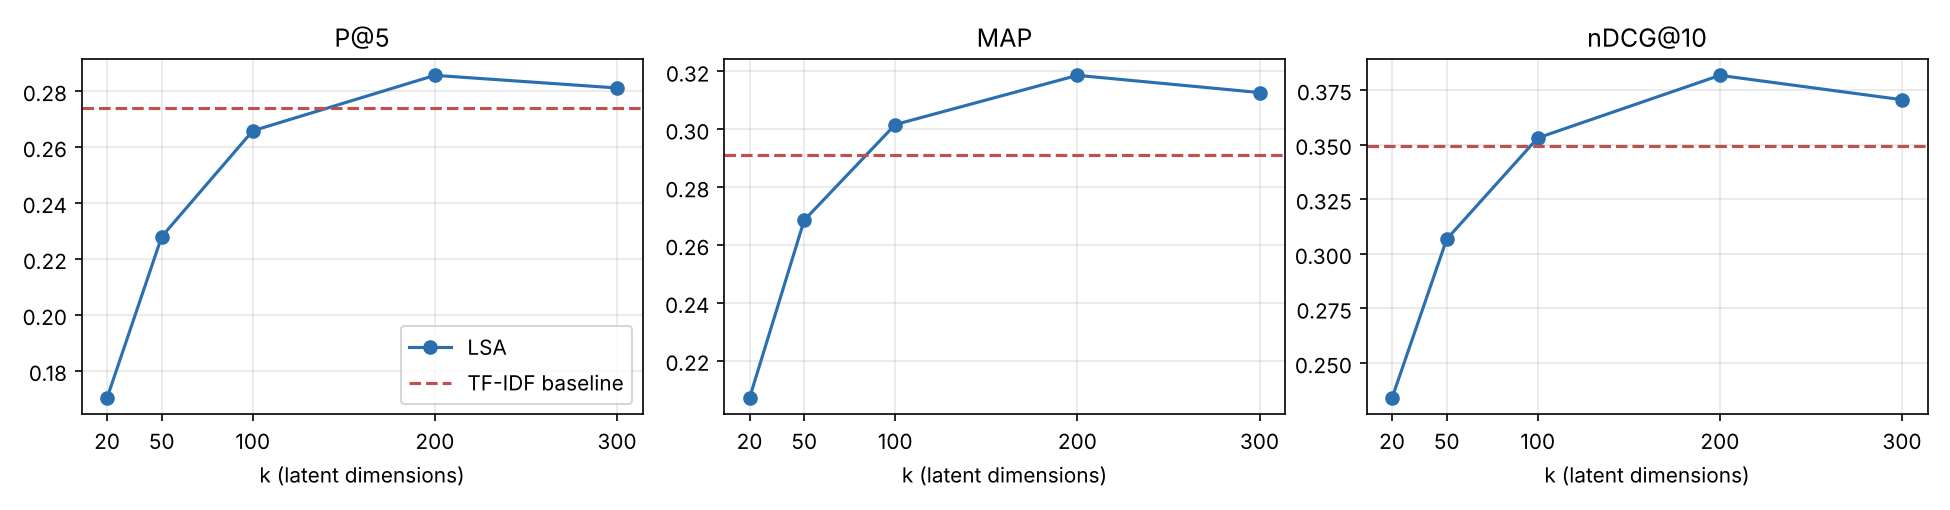

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
lsa_part = k_table[k_table.system == "LSA"]
for a, m in zip(ax, ["P@5", "MAP", "nDCG@10"]):
    a.plot(lsa_part["k (dims)"], lsa_part[m], marker="o", color="#2a6fb0", label="LSA")
    a.axhline(base[m], color="#c0504d", ls="--", label="TF-IDF baseline")
    a.set(title=m, xlabel="k (latent dimensions)", xticks=K_VALUES)
    a.grid(alpha=0.3)
ax[0].legend()
plt.tight_layout(); plt.savefig(OUT / "figures" / "metrics_vs_k.png", dpi=150); plt.close()
display(Image(str(OUT / "figures" / "metrics_vs_k.png")))

**Discussion — effect of the number of dimensions.**

| k | explained variance | P@5 | MAP | nDCG@10 | vs. TF-IDF |
|---|---|---|---|---|---|
| 20 | 18.7 % | 0.170 | 0.207 | 0.234 | much worse: 20 topics are too coarse for 225 specific technical queries |
| 50 | 31.2 % | 0.228 | 0.269 | 0.307 | worse on every metric (−8 % MAP, −12 % nDCG@10) |
| 100 | 43.9 % | 0.266 | 0.302 | 0.353 | about equal (MAP +3.6 %, nDCG@10 +1.0 %, P@5 −3 %) |
| **200** | 59.8 % | **0.286** | **0.319** | **0.382** | **best: P@5 +4.3 %, MAP +9.4 %, nDCG@10 +9.2 %** |
| 300 | 70.4 % | 0.281 | 0.313 | 0.371 | still better, but falling back toward TF-IDF |

* Retrieval quality first rises with k and then falls slightly. Small k merges too many concepts (the qid 136 effect).
  As k approaches the rank of the matrix, LSA becomes TF-IDF again and loses its smoothing benefit.
  For this small, technical collection the best value is around **k ≈ 200**. The k = 50 suggested in the lab handout is
  too aggressive here.
* Explained variance is low: 50 components keep only 31 % of the variance, because a short-abstract TF-IDF matrix
  is very sparse and high-rank. Explained variance alone is therefore a poor guide for choosing k, and it should be
  tuned on retrieval metrics.
* The randomized SVD is stable: over 5 seeds the k = 50 metrics vary by at most ±0.003.
* **Runtime** (table above). The SVD (indexing) cost grows roughly linearly with k, from about 0.1 s at k = 20 to over
  1 s at k = 300, on top of building the TF-IDF matrix. Query time (folding in, scoring and sorting 225 queries) stays
  at a few tens of milliseconds for every configuration. At this scale it is dominated by sorting, so it hardly changes with k. On a large collection the
  dense k-dimensional document vectors would be much smaller than the sparse vocabulary-sized vectors, but they could
  no longer be searched with an inverted index.

## Part 4 — Word embeddings with Word2Vec

**Training corpus.** The same 1,400 documents (title + abstract), split into sentences at full stops,
lower-cased, tokenised with the same tokenizer and stop-word list as Part 1. Stemming is **not** applied here
so that nearest neighbours are readable words (e.g. `aerodynamic` rather than the stem `aerodynam`).

**Configurations** (identical except the architecture):

| parameter | value |
|---|---|
| `vector_size` | 100 |
| `window` | 5 |
| `min_count` | 5 (words seen fewer than 5 times get unreliable vectors on a corpus this small) |
| `negative` sampling | 10 (no hierarchical softmax) |
| `sample` (down-sampling) | 1e-3 |
| `epochs` | 30 (the corpus is small, ~130k tokens, so many passes are needed) |
| `sg` | 0 = **CBOW**, 1 = **Skip-gram** |

`workers=1`, a fixed seed and a deterministic hash function make the runs reproducible.

In [19]:
def sentences_of(text):
    for s in re.split(r"\s\.\s|\s\.$|\.\s", text.lower()):
        toks = tokenize(s)
        if len(toks) >= 2:
            yield toks

sentences = [s for t in docs_df["text"] for s in sentences_of(t)]
n_tok = sum(len(s) for s in sentences)
print(f"sentences: {len(sentences):,}   tokens: {n_tok:,}   distinct words: {len(set(w for s in sentences for w in s)):,}")
print("example:", sentences[0])

def stable_hash(s):
    return zlib.crc32(s.encode("utf-8"))

W2V_PARAMS = dict(vector_size=100, window=5, min_count=5, negative=10, hs=0, sample=1e-3,
                  epochs=30, workers=1, seed=SEED, hashfxn=stable_hash)
models, train_times = {}, {}
for name, sg in [("CBOW", 0), ("Skip-gram", 1)]:
    t0 = time.perf_counter()
    models[name] = Word2Vec(sentences=sentences, sg=sg, **W2V_PARAMS)
    train_times[name] = time.perf_counter() - t0
    print(f"{name:9s}: vocabulary {len(models[name].wv):,} words, training time {train_times[name]:.1f} s")
w2v_vocab = models["CBOW"].wv.index_to_key
RESULTS["w2v"] = {"sentences": len(sentences), "tokens": n_tok, "vocab": len(w2v_vocab),
                  "train_time_s": train_times}

sentences: 11,413   tokens: 131,618   distinct words: 6,749
example: ['experimental', 'investigation', 'aerodynamics', 'wing', 'slipstream']


CBOW     : vocabulary 2,697 words, training time 11.4 s


Skip-gram: vocabulary 2,697 words, training time 36.4 s


### 4.1 Five nearest words (cosine similarity) for selected terms — CBOW vs Skip-gram

In [20]:
TERMS = ["supersonic", "turbulent", "wing", "heat", "shock", "buckling", "aerofoil", "nozzle"]
assert all(t in models["CBOW"].wv for t in TERMS)

def nn_str(neigh):
    return ", ".join(f"{w} ({s:.2f})" for w, s in neigh)

rows = []
for t in TERMS:
    c = models["CBOW"].wv.most_similar(t, topn=5)
    s = models["Skip-gram"].wv.most_similar(t, topn=5)
    rows.append({"term": t, "freq": models["CBOW"].wv.get_vecattr(t, "count"),
                 "CBOW top-5": nn_str(c), "Skip-gram top-5": nn_str(s),
                 "shared": len({w for w, _ in c} & {w for w, _ in s})})
nn_table = pd.DataFrame(rows).set_index("term")
nn_table.to_csv(OUT / "tables" / "w2v_nearest_neighbours.csv")
display(nn_table)
RESULTS["w2v_neighbours"] = nn_table.reset_index().to_dict("records")

,freq,CBOW top-5,Skip-gram top-5,shared
term,,,,
supersonic,629,"transonic (0.57), subsonic (0.54), traveling (0.53), uncambered (0.51), wakes (0.49)","subsonic (0.56), overexpanded (0.54), intakes (0.53), spiked (0.52), uncambered (0.51)",2
turbulent,353,"separated (0.52), turbulence (0.50), laminar (0.48), zone (0.46), boundary (0.40)","laminar (0.57), boundary (0.54), layer (0.51), turbulence (0.51), stabilization (0.51)",3
wing,641,"wings (0.68), cropped (0.61), tail (0.60), arrangements (0.59), flaps (0.56)","wings (0.62), cropped (0.58), tail (0.58), tilt (0.58), tilting (0.57)",3
heat,749,"mass (0.47), isothermal (0.46), heating (0.46), shield (0.44), diffusion (0.43)","transfer (0.79), shield (0.62), refractory (0.58), transpiration (0.54), protection (0.52)",1
shock,794,"bow (0.60), originating (0.55), detached (0.55), weak (0.52), blast (0.52)","wave (0.67), attenuation (0.57), incident (0.57), driver (0.56), striking (0.56)",0
buckling,371,"deformations (0.64), wrinkling (0.60), buckle (0.53), columns (0.53), vessels (0.52)","rings (0.61), unstiffened (0.60), postbuckling (0.58), unpressurized (0.58), stiffened (0.58)",0
aerofoil,35,"airfoil (0.49), wings (0.48), discs (0.48), delta (0.47), tapered (0.47)","inverted (0.52), discs (0.52), split (0.52), tapered (0.50), mapping (0.50)",2
nozzle,200,"exit (0.64), nozzles (0.60), convergent (0.59), exhaust (0.56), converging (0.52)","exit (0.65), laval (0.58), nozzles (0.57), throat (0.55), choked (0.54)",2


In [21]:
# Quantitative comparison of the two configurations
def top_set(model, w, n=10):
    return {x for x, _ in model.wv.most_similar(w, topn=n)}

frequent = [w for w in w2v_vocab[:1000]]
jac = [len(top_set(models["CBOW"], w) & top_set(models["Skip-gram"], w)) /
       len(top_set(models["CBOW"], w) | top_set(models["Skip-gram"], w)) for w in frequent]
print(f"mean Jaccard of the top-10 neighbour sets, CBOW vs Skip-gram, over the 1,000 most frequent words: {np.mean(jac):.3f}")

# Related / unrelated word pairs chosen from aerodynamics vocabulary
RELATED = [("supersonic", "hypersonic"), ("laminar", "turbulent"), ("aerofoil", "airfoil"), ("wing", "aerofoil"),
           ("temperature", "heat"), ("cylinder", "cone"), ("buckling", "shells"), ("shock", "wave"),
           ("nozzle", "jet"), ("viscous", "inviscid"), ("lift", "drag"), ("plate", "plates")]
rng = np.random.default_rng(SEED)
mid = [w for w in w2v_vocab[100:2000]]
RANDOM = [tuple(rng.choice(mid, 2, replace=False)) for _ in range(500)]
pair_rows = []
for name, m in models.items():
    rel = np.mean([m.wv.similarity(a, b) for a, b in RELATED])
    rnd = np.mean([m.wv.similarity(a, b) for a, b in RANDOM])
    pair_rows.append({"model": name, "mean cos (related pairs)": rel, "mean cos (random pairs)": rnd,
                      "gap": rel - rnd, "train time (s)": train_times[name]})
cfg_table = pd.DataFrame(pair_rows).set_index("model")
display(cfg_table.round(3))
RESULTS["w2v_config_compare"] = {"jaccard_top10_cbow_vs_sg": float(np.mean(jac)),
                                 **{k: v for k, v in cfg_table.round(4).to_dict("index").items()}}

mean Jaccard of the top-10 neighbour sets, CBOW vs Skip-gram, over the 1,000 most frequent words: 0.207


,mean cos (related pairs),mean cos (random pairs),gap,train time (s)
model,,,,
CBOW,0.464,0.059,0.405,11.364
Skip-gram,0.492,0.198,0.294,36.443


**CBOW vs Skip-gram.**

* **Neighbour type.** CBOW (which predicts a word from the average of its context) returns words that can **replace**
  the target in a sentence: *supersonic → transonic, subsonic*; *buckling → deformations, wrinkling, buckle*;
  *aerofoil → airfoil, wings, delta*. Skip-gram (which predicts each context word from the target) returns more
  **topical associates**, including rarer, specific words: *heat → transfer, shield, refractory, transpiration*
  (the heat-shield topic); *buckling → rings, unstiffened, stiffened, postbuckling*; *shock → wave, attenuation, incident*.
* **Agreement.** Only about 21 % of the top-10 neighbours are shared on average (Jaccard 0.207 over the 1,000 most
  frequent words), so the two architectures learn noticeably different spaces from the same 130k tokens.
* **Separation.** Both give clearly higher cosine to the hand-picked related pairs than to random pairs. CBOW has the
  larger gap (0.405 vs 0.294). Skip-gram gives even random pairs a fairly high cosine (0.20), so its similarity values
  must be read relative to that baseline.
* **Cost.** Skip-gram makes one prediction per (word, context word) pair instead of one per window, so it trained
  about 3× slower than CBOW (see the training times in the table, one thread).

### 4.2 Comparison with count-based word similarity

Two count-based term representations are built on the **same unstemmed tokens and vocabulary** as Word2Vec:

* **TF-IDF (document-level)** — each word is a column of the document–term TF-IDF matrix; two words are similar
  when they occur in the **same documents** (first-order co-occurrence / word overlap).
* **PPMI co-occurrence (window-level)** — word × context counts within a ±5 word window inside sentences,
  re-weighted by positive pointwise mutual information; each word is a row, compared with cosine.

In [22]:
w_index = {w: i for i, w in enumerate(w2v_vocab)}
V = len(w2v_vocab)

# (a) TF-IDF term vectors: columns of a doc x word TF-IDF matrix over the unstemmed vocabulary
tfidf_words = TfidfVectorizer(analyzer=lambda t: [w for w in tokenize(t) if w in w_index])
Xw = tfidf_words.fit_transform(docs_df["text"])
term_vecs_tfidf = Xw.T.tocsr()
tfidf_w_index = tfidf_words.vocabulary_

# (b) PPMI over a +-5 word window
rows_, cols_ = [], []
for s in sentences:
    ids = [w_index[w] for w in s if w in w_index]
    for i, wi in enumerate(ids):
        for j in range(max(0, i - 5), min(len(ids), i + 6)):
            if j != i:
                rows_.append(wi); cols_.append(ids[j])
C = sp.coo_matrix((np.ones(len(rows_)), (rows_, cols_)), shape=(V, V)).tocsr()
total = C.sum()
row_sum = np.asarray(C.sum(1)).ravel(); col_sum = np.asarray(C.sum(0)).ravel()
Cc = C.tocoo()
pmi = np.log((Cc.data * total) / (row_sum[Cc.row] * col_sum[Cc.col]))
keep = pmi > 0
PPMI = sp.csr_matrix((pmi[keep], (Cc.row[keep], Cc.col[keep])), shape=(V, V))
print(f"TF-IDF word matrix: {Xw.shape};  co-occurrence matrix: {C.shape}, PPMI non-zeros: {PPMI.nnz:,}")

# Document frequency and number of documents in which two words co-occur (word overlap)
doc_sets = [set(tokenize(t)) for t in docs_df["text"]]
def df_both(a, b):
    return sum(1 for s in doc_sets if a in s and b in s)

def count_neighbours(mat, idx, inv, w, n=5):
    v = mat[idx[w]]
    sims = cosine_similarity(v, mat).ravel()
    sims[idx[w]] = -1
    top = np.argsort(-sims)[:n]
    return [(inv[i], float(sims[i])) for i in top]

inv_tfidf = {i: w for w, i in tfidf_w_index.items()}
inv_w = dict(enumerate(w2v_vocab))
rows = []
for t in TERMS:
    rows.append({"term": t,
                 "TF-IDF (same documents)": nn_str(count_neighbours(term_vecs_tfidf, tfidf_w_index, inv_tfidf, t)),
                 "PPMI (window co-occurrence)": nn_str(count_neighbours(PPMI, w_index, inv_w, t)),
                 "Skip-gram": nn_str(models["Skip-gram"].wv.most_similar(t, topn=5))})
count_table = pd.DataFrame(rows).set_index("term")
count_table.to_csv(OUT / "tables" / "count_vs_w2v_neighbours.csv")
display(count_table)
RESULTS["count_neighbours"] = count_table.reset_index().to_dict("records")

TF-IDF word matrix: (1400, 2697);  co-occurrence matrix: (2697, 2697), PPMI non-zeros: 364,696


,TF-IDF (same documents),PPMI (window co-occurrence),Skip-gram
term,,,
supersonic,"flow (0.34), speeds (0.31), mach (0.30), theory (0.28), pressure (0.25)","subsonic (0.33), speeds (0.31), wings (0.28), flow (0.28), bodies (0.28)","subsonic (0.56), overexpanded (0.54), intakes (0.53), spiked (0.52), uncambered (0.51)"
turbulent,"boundary (0.35), layer (0.34), layers (0.28), friction (0.26), laminar (0.25)","laminar (0.37), boundary (0.35), layers (0.32), layer (0.31), transfer (0.24)","laminar (0.57), boundary (0.54), layer (0.51), turbulence (0.51), stabilization (0.51)"
wing,"wings (0.30), aspect (0.30), lift (0.30), combinations (0.30), body (0.29)","wings (0.43), tail (0.35), chord (0.33), trailing (0.31), flaps (0.31)","wings (0.62), cropped (0.58), tail (0.58), tilt (0.58), tilting (0.57)"
heat,"transfer (0.83), temperature (0.40), conduction (0.39), laminar (0.35), stagnation (0.30)","transfer (0.69), temperature (0.34), conduction (0.32), laminar (0.30), surface (0.28)","transfer (0.79), shield (0.62), refractory (0.58), transpiration (0.54), protection (0.52)"
shock,"wave (0.54), waves (0.47), interaction (0.29), detached (0.28), driver (0.27)","wave (0.55), waves (0.43), tube (0.29), reflected (0.28), flow (0.27)","wave (0.67), attenuation (0.57), incident (0.57), driver (0.56), striking (0.56)"
buckling,"shells (0.45), columns (0.41), axial (0.38), compression (0.36), creep (0.35)","shells (0.50), cylindrical (0.39), cylinders (0.37), plates (0.35), plastic (0.34)","rings (0.61), unstiffened (0.60), postbuckling (0.58), unpressurized (0.58), stiffened (0.58)"
aerofoil,"split (0.30), calculating (0.26), ground (0.24), formulae (0.24), aerofoils (0.21)","split (0.19), calculate (0.18), rae (0.18), circle (0.18), deg (0.18)","inverted (0.52), discs (0.52), split (0.52), tapered (0.50), mapping (0.50)"
nozzle,"nozzles (0.52), exit (0.32), expanded (0.32), convergent (0.30), throat (0.30)","exit (0.37), jet (0.31), nozzles (0.28), throat (0.28), diameters (0.26)","exit (0.65), laval (0.58), nozzles (0.57), throat (0.55), choked (0.54)"


In [23]:
def cos_tfidf(a, b):
    return float(cosine_similarity(term_vecs_tfidf[tfidf_w_index[a]], term_vecs_tfidf[tfidf_w_index[b]])[0, 0])
def cos_ppmi(a, b):
    return float(cosine_similarity(PPMI[w_index[a]], PPMI[w_index[b]])[0, 0])
lsa_term_vecs = lsa_runs[100]["svd"].components_.T * lsa_runs[100]["svd"].singular_values_
def cos_lsa(a, b):
    ia, ib = tfidf.vocabulary_[stem(a)], tfidf.vocabulary_[stem(b)]
    return float(cosine_similarity(lsa_term_vecs[[ia]], lsa_term_vecs[[ib]])[0, 0])

pair_table = pd.DataFrame([{
    "pair": f"{a} – {b}", "df(a)": sum(a in s for s in doc_sets), "df(b)": sum(b in s for s in doc_sets),
    "docs with both": df_both(a, b), "TF-IDF cos": cos_tfidf(a, b), "PPMI cos": cos_ppmi(a, b),
    "LSA k=100 cos": cos_lsa(a, b),
    "CBOW cos": float(models["CBOW"].wv.similarity(a, b)), "Skip-gram cos": float(models["Skip-gram"].wv.similarity(a, b))}
    for a, b in RELATED]).set_index("pair")
print("LSA k=100 cos: cosine of the stems' rows of V_k*Sigma_k from Part 2 (1.0 when both words share a stem)")
pair_table.to_csv(OUT / "tables" / "word_pair_similarities.csv")
display(pair_table.round(3))

# Agreement between the similarity measures over all pairs of the 300 most frequent words
from scipy.stats import spearmanr
top_words = w2v_vocab[:300]
iu = np.triu_indices(len(top_words), 1)
S = {
    "TF-IDF": cosine_similarity(term_vecs_tfidf[[tfidf_w_index[w] for w in top_words]])[iu],
    "PPMI": cosine_similarity(PPMI[[w_index[w] for w in top_words]])[iu],
    "CBOW": cosine_similarity(models["CBOW"].wv[top_words])[iu],
    "Skip-gram": cosine_similarity(models["Skip-gram"].wv[top_words])[iu],
}
corr = pd.DataFrame({a: {b: spearmanr(S[a], S[b]).statistic for b in S} for a in S})
print(f"Spearman correlation of pairwise similarities ({len(iu[0]):,} pairs of the 300 most frequent words):")
display(corr.round(3))
RESULTS["pair_table"] = pair_table.round(4).reset_index().to_dict("records")
RESULTS["similarity_correlation"] = corr.round(4).to_dict()

LSA k=100 cos: cosine of the stems' rows of V_k*Sigma_k from Part 2 (1.0 when both words share a stem)


,df(a),df(b),docs with both,TF-IDF cos,PPMI cos,LSA k=100 cos,CBOW cos,Skip-gram cos
pair,,,,,,,,
supersonic – hypersonic,267,170,28,0.086,0.182,0.088,0.467,0.409
laminar – turbulent,233,127,70,0.247,0.369,0.258,0.485,0.566
aerofoil – airfoil,18,53,1,0.013,0.147,-0.032,0.488,0.286
wing – aerofoil,181,18,4,0.035,0.133,0.080,0.456,0.380
temperature – heat,250,254,138,0.399,0.341,0.511,0.382,0.473
cylinder – cone,131,92,22,0.142,0.349,0.088,0.384,0.424
buckling – shells,120,85,51,0.449,0.505,0.427,0.444,0.573
shock – wave,237,168,117,0.538,0.547,0.719,0.345,0.674
nozzle – jet,71,92,26,0.267,0.308,0.246,0.475,0.479


Spearman correlation of pairwise similarities (44,850 pairs of the 300 most frequent words):


,TF-IDF,PPMI,CBOW,Skip-gram
TF-IDF,1.000,0.664,0.368,0.403
PPMI,0.664,1.000,0.542,0.515
CBOW,0.368,0.542,1.000,0.662
Skip-gram,0.403,0.515,0.662,1.000


**Count-based vs embedding similarity.**

* **TF-IDF (document-level)** neighbours are words that appear **in the same abstracts**. These are topical
  associates such as *supersonic → flow, speeds, mach, theory, pressure*, and the score is high only when the two
  words actually co-occur in documents (*heat–transfer* 0.83, *shock–wave* 0.54).
* **PPMI (window-level)** neighbours are already closer to Word2Vec (*supersonic → subsonic*, *wing → wings, tail,
  chord, flaps*), because they also use local context instead of whole documents.
* The rank correlation table supports this. Word2Vec similarities correlate more with window PPMI (ρ ≈ 0.52–0.54)
  than with document TF-IDF (ρ ≈ 0.37–0.40). This is consistent with the known result that skip-gram with negative
  sampling implicitly factorises a (shifted) PMI word–context matrix.
* The pair table shows the main difference. Words that **substitute for each other** but seldom appear in the same
  abstract get almost zero TF-IDF similarity: *aerofoil–airfoil* 0.013, *wing–aerofoil* 0.035, *supersonic–hypersonic*
  0.086. CBOW gives them 0.46–0.49. Pairs that co-occur constantly (*shock–wave*, *temperature–heat*) score well
  under every method. LSA term vectors (k = 100) behave like smoothed TF-IDF: they help when the documents themselves
  overlap (*viscous–inviscid* 0.27 → 0.56, *shock–wave* 0.54 → 0.72) but not for the spelling variants. Stemming,
  on the other hand, trivially merges *plate/plates* (cos 1.0).

### 4.3 A relationship that embeddings capture but word overlap misses

Search systematically for such cases: among the Skip-gram top-10 neighbours of frequent words, find pairs with
**high embedding similarity** but that **rarely or never appear in the same document** (so their document-level
TF-IDF similarity is low).

In [24]:
cands = []
for w in w2v_vocab[:1500]:
    for n, s in models["Skip-gram"].wv.most_similar(w, topn=10):
        if w < n:
            cands.append((w, n, s))
cand_df = pd.DataFrame(cands, columns=["a", "b", "skipgram"]).drop_duplicates(["a", "b"])
cand_df["docs with both"] = [df_both(a, b) for a, b in zip(cand_df.a, cand_df.b)]
cand_df["TF-IDF cos"] = [cos_tfidf(a, b) for a, b in zip(cand_df.a, cand_df.b)]
cand_df["min df"] = [min(sum(a in s for s in doc_sets), sum(b in s for s in doc_sets)) for a, b in zip(cand_df.a, cand_df.b)]
gap = cand_df[(cand_df["min df"] >= 15)].sort_values(["docs with both", "skipgram"], ascending=[True, False])
display(gap.head(12).round(3))

,a,b,skipgram,docs with both,TF-IDF cos,min df
5433,patterns,schlieren,0.579,0,0.0,16
2680,integration,solving,0.568,0,0.0,23
5991,rayleigh,solving,0.553,0,0.0,17
4596,evidence,quantitative,0.546,0,0.0,16
1474,diameter,width,0.545,0,0.0,21
4954,expansions,rayleigh,0.545,0,0.0,16
5294,nondimensional,plotted,0.540,0,0.0,15
7003,excellent,gave,0.539,0,0.0,15
4775,better,reasonable,0.538,0,0.0,23
4776,better,quantitative,0.531,0,0.0,16


In [25]:
A, B = "aerofoil", "airfoil"
print(f"'{A}' occurs in {sum(A in s for s in doc_sets)} documents, '{B}' in {sum(B in s for s in doc_sets)}; "
      f"documents containing both: {df_both(A, B)}")
print(f"TF-IDF (document) cosine: {cos_tfidf(A, B):.3f}   PPMI cosine: {cos_ppmi(A, B):.3f}   "
      f"CBOW: {models['CBOW'].wv.similarity(A, B):.3f}   Skip-gram: {models['Skip-gram'].wv.similarity(A, B):.3f}")
for name, m in models.items():
    order = [w for w, _ in m.wv.most_similar(A, topn=len(m.wv) - 1)]
    print(f"rank of '{B}' among the {name} neighbours of '{A}': {order.index(B) + 1} of {len(order)}")
print(f"LSA (k=100) cosine of the stems: {cos_lsa(A, B):.3f}")

# Shared contexts: the words that most often appear within the window of each spelling
ctx = lambda w: Counter({inv_w[j]: int(c) for j, c in zip(C[w_index[w]].indices, C[w_index[w]].data)})
ca, cb = ctx(A), ctx(B)
shared = sorted(set(ca) & set(cb), key=lambda w: -(ca[w] + cb[w]))[:15]
print("\nmost frequent shared context words:", ", ".join(f"{w} ({ca[w]}/{cb[w]})" for w in shared))

# Retrieval consequence: with the TF-IDF baseline, a query that says "airfoil" cannot match a document that
# only says "aerofoil" (the stems differ: "aerofoil" vs "airfoil").
print("\nstems:", stem(A), "/", stem(B))
qs = queries_df[queries_df.text.str.contains(f"{A}|{B}")]
for q in qs.itertuples():
    if q.qid not in eval_qids:
        continue
    rel_docs = relevant[q.qid]
    word_in = lambda w: sum(w in doc_sets[d - 1] for d in rel_docs)
    print(f"qid {q.qid}: '{q.text[:90]}'\n    {len(rel_docs)} relevant docs: {word_in(A)} contain '{A}', {word_in(B)} contain '{B}'")
    qword = B if B in tokenize(q.text) else A
    other = A if qword == B else B
    for d in sorted(rel_docs):
        if other in doc_sets[d - 1] and qword not in doc_sets[d - 1]:
            rank = lambda ranked: int(np.where(ranked[q.qid - 1] == d)[0][0]) + 1
            print(f"      doc {d} says '{other}' but never '{qword}': rank TF-IDF {rank(ranked_tfidf)}, "
                  f"LSA k=100 {rank(lsa_runs[100]['ranked'])}, LSA k=200 {rank(lsa_runs[200]['ranked'])}")

'aerofoil' occurs in 18 documents, 'airfoil' in 53; documents containing both: 1
TF-IDF (document) cosine: 0.013   PPMI cosine: 0.147   CBOW: 0.488   Skip-gram: 0.286
rank of 'airfoil' among the CBOW neighbours of 'aerofoil': 1 of 2696
rank of 'airfoil' among the Skip-gram neighbours of 'aerofoil': 450 of 2696
LSA (k=100) cosine of the stems: -0.032

most frequent shared context words: flow (3/37), theory (10/21), pressure (3/24), lift (3/21), mach (4/17), distribution (4/17), section (3/17), dimensional (5/15), velocity (4/12), given (4/11), number (3/12), surface (2/11), transonic (1/10), numbers (2/9), stream (1/10)

stems: aerofoil / airfoil
qid 42: 'what is a criterion that the transonic flow around an airfoil with a round leading edge be'
    4 relevant docs: 2 contain 'aerofoil', 3 contain 'airfoil'
      doc 468 says 'aerofoil' but never 'airfoil': rank TF-IDF 6, LSA k=100 5, LSA k=200 5
qid 43: 'can the transonic flow around an arbitrary smooth thin airfoil be analysed in a si

**Example — "aerofoil" vs "airfoil".** The Cranfield abstracts use both the British spelling *aerofoil*
(18 documents) and the American spelling *airfoil* (53 documents) for the same object. Only **one** document
contains both, so any method based on word overlap treats them as unrelated:

* exact matching / TF-IDF: the stems differ (`aerofoil` ≠ `airfoil`), so a query that says *airfoil* gets no credit
  from a document that says *aerofoil*. The document-level TF-IDF cosine of the two words is **0.013**;
* LSA (k = 100): **−0.03**. The two spellings occur in disjoint sets of documents, so the document-level SVD does not
  connect them either.

**CBOW** puts *airfoil* as the **nearest neighbour of aerofoil** (rank 1 of 2,696 words, cosine 0.49). Word2Vec never
needs the two words to occur together. It only needs them to occur in **similar contexts**, and both appear next
to *theory, pressure, lift, distribution, section, mach, velocity, transonic, flow* (the shared-context list above).
Because CBOW is trained to predict a word from its context, two words that fill the same slot get similar vectors.
This is a second-order (distributional) relation, which first-order word overlap cannot see. The same effect gives
pairs such as *diameter–width* and *integration–solving* (0 shared documents, Skip-gram cosine ≈ 0.55) in the
systematic search above.

In retrieval this matters for queries 42 and 43 ("transonic flow around an *airfoil*"): relevant doc 468 only says
*aerofoil*. TF-IDF still finds it (ranks 6 and 12), but only through the other shared words (*transonic, flow*),
not through the key term. Expanding the query with Word2Vec neighbours would close that gap.

Skip-gram ranks *airfoil* only 450th for *aerofoil*. With just 35 occurrences of *aerofoil*, Skip-gram
fits the word's specific co-occurring terms (*split, discs, inverted*) instead of its general slot. On a corpus
this small, CBOW's context averaging gives the more robust substitute relation.

*Note:* Word2Vec vectors are **static**, one vector per word type learnt from its contexts. Fully contextual models
such as BERT would also tell apart different senses of the same word in different sentences.

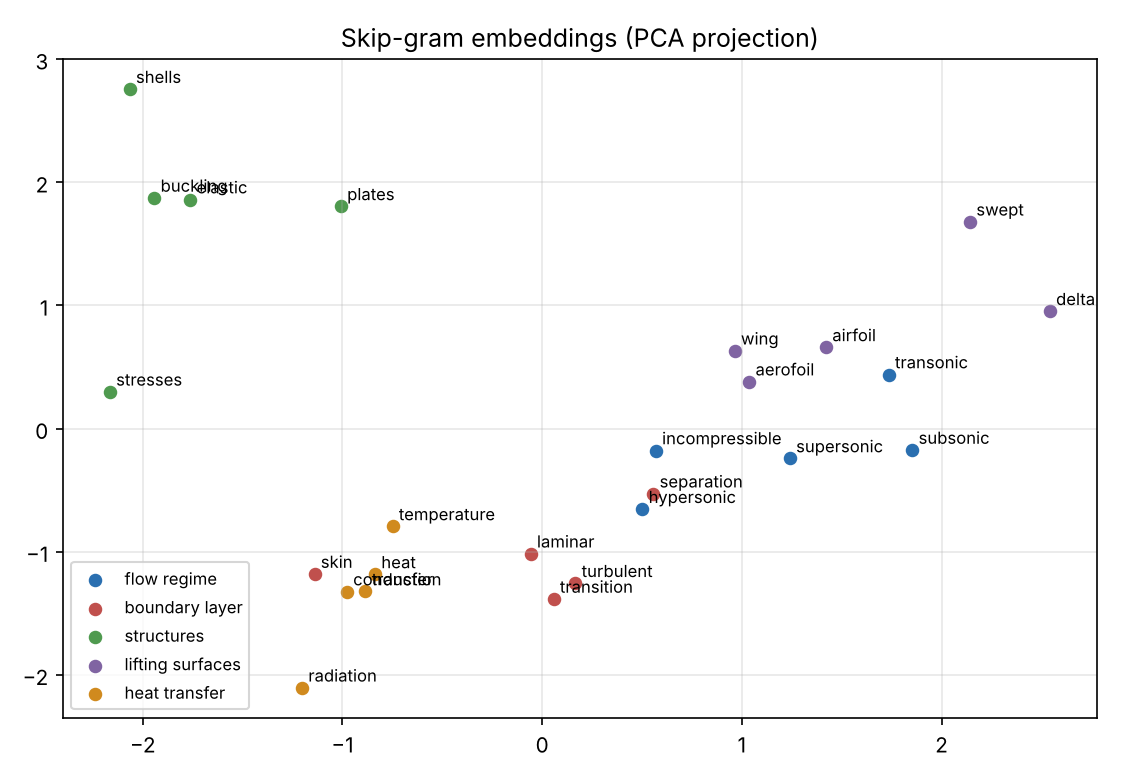

In [26]:
# 2-D PCA view of the Skip-gram space for a few semantic groups
from sklearn.decomposition import PCA
groups = {"flow regime": ["supersonic", "hypersonic", "subsonic", "transonic", "incompressible"],
          "boundary layer": ["laminar", "turbulent", "transition", "separation", "skin"],
          "structures": ["buckling", "shells", "plates", "stresses", "elastic"],
          "lifting surfaces": ["wing", "aerofoil", "airfoil", "delta", "swept"],
          "heat transfer": ["heat", "temperature", "conduction", "transfer", "radiation"]}
words = [w for g in groups.values() for w in g if w in models["Skip-gram"].wv]
P = PCA(n_components=2, random_state=SEED).fit_transform(models["Skip-gram"].wv[words])
colors = dict(zip(groups, ["#2a6fb0", "#c0504d", "#4f9a4f", "#8064a2", "#d08a1e"]))
fig, ax = plt.subplots(figsize=(7.5, 5.2))
for g, ws in groups.items():
    idx = [words.index(w) for w in ws if w in words]
    ax.scatter(P[idx, 0], P[idx, 1], color=colors[g], label=g, s=30)
    for i in idx:
        ax.annotate(words[i], P[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.legend(fontsize=8); ax.grid(alpha=0.3); ax.set_title("Skip-gram embeddings (PCA projection)")
plt.tight_layout(); plt.savefig(OUT / "figures" / "skipgram_pca.png", dpi=150); plt.close()
display(Image(str(OUT / "figures" / "skipgram_pca.png")))

## Summary of results

In [27]:
print(f"Evaluated queries: {len(eval_qids)} of {len(queries_df)} (relevance = grade 1-3, nDCG gain = 4 - grade)\n")
display(k_table[["system", "k (dims)", "explained var.", "P@5", "MAP", "MAP@10", "nDCG@10",
                 "fit time (s)", "query time (s)"]].round(4))
with open(OUT / "results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved -> outputs/results.json")

Evaluated queries: 222 of 225 (relevance = grade 1-3, nDCG gain = 4 - grade)



,system,k (dims),explained var.,P@5,MAP,MAP@10,nDCG@10,fit time (s),query time (s)
0,TF-IDF,4170,1.0000,0.2739,0.2912,0.2441,0.3495,0.1632,0.0260
1,LSA,20,0.1867,0.1703,0.2071,0.1596,0.2340,0.1216,0.0579
2,LSA,50,0.3115,0.2279,0.2685,0.2186,0.3067,0.2045,0.0366
3,LSA,100,0.4389,0.2658,0.3016,0.2509,0.3531,0.4466,0.0358
4,LSA,200,0.5979,0.2856,0.3187,0.2738,0.3817,0.7853,0.0363
5,LSA,300,0.7036,0.2811,0.3127,0.2634,0.3706,1.2452,0.0321


saved -> outputs/results.json


## Conclusions

1. **TF-IDF baseline:** 1,400 documents, 225 queries (222 with relevant documents), a 4,170-stem vocabulary and a
   1400 × 4170 matrix that is 98.7 % sparse. It reaches P@5 0.274, MAP 0.291, nDCG@10 0.350.
2. **LSA (k = 50):** keeps 31 % of the variance and places documents (1400 × 50) and queries (225 × 50) in a dense latent
   space. It is **worse** than TF-IDF on this collection (MAP 0.269, nDCG@10 0.307). It helps queries whose relevant
   documents use different vocabulary (qid 184: nDCG@10 0 → 0.70), and it hurts precise queries where a rare term
   picks out the relevant paper within a cluster of similar ones (qid 136: AP 1.0 → 0.13).
3. **Dimensionality:** quality peaks at **k ≈ 200** (P@5 0.286, MAP 0.319, nDCG@10 0.382, about +9 % MAP/nDCG over
   TF-IDF). k = 100 ties with the baseline, and k = 20 and 50 are too coarse. Indexing cost grows with k, while query
   cost stays well under 1 ms per query.
4. **Word2Vec:** CBOW gives substitutable neighbours (*supersonic → transonic, subsonic*), and Skip-gram gives
   topical associates (*heat → transfer, shield, refractory*). Both agree more with window-based PPMI than with
   document-level TF-IDF. Embeddings capture relations that word overlap misses, such as the spelling variants
   *aerofoil/airfoil* (TF-IDF cosine 0.01, CBOW nearest neighbour).